# 1. Introdução

## Validação cruzada dos modelos

Este notebook tem como objetivo avaliar a estabilidade e a capacidade de
generalização dos modelos de Regressão Logística, Random Forest e
MLPClassifier.

Será utilizada validação cruzada estratificada com cinco divisões. Em cada
divisão, o modelo será treinado em uma parte dos dados de treino e avaliado
na parte restante.

O conjunto de teste não será utilizado durante a validação cruzada, sendo
preservado para a avaliação final dos modelos selecionados.

## Objetivos

- Aplicar validação cruzada estratificada aos três modelos;
- Calcular as métricas em cada divisão;
- Comparar média e desvio-padrão dos resultados;
- Verificar a estabilidade dos modelos;
- Identificar possíveis sinais de sobreajuste;
- Manter o F1-score da classe churn como métrica técnica principal.

## Configuração dos experimentos

Todos os modelos utilizaram a mesma divisão estratificada entre treino e
teste, com 80% dos dados para treino e 20% para teste. A validação cruzada
foi executada somente sobre o conjunto de treino, utilizando
StratifiedKFold com cinco divisões.

| Modelo | Configuração principal |
|---|---|
| Regressão Logística | max_iter=1000 |
| Random Forest | n_estimators=200 |
| MLPClassifier | uma camada oculta com 32 neurônios, ReLU, Adam, alpha=0.001, max_iter=300 e early stopping |

# 2. Importações

In [25]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from pathlib import Path
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    train_test_split,
)
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "Churn Value"

# 3. Carregamento e preparação

In [3]:
df = pd.read_parquet("../data/processed/dataset.parquet")

columns_to_drop = [
    TARGET,
    "CustomerID",
    "Churn Label",
    "Churn Score",
    "Churn Reason",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
]

columns_to_drop = [
    column for column in columns_to_drop
    if column in df.columns
]

X = df.drop(columns=columns_to_drop)
y = df[TARGET].astype(int)

print(f"Features: {X.shape}")
print(f"Target: {y.shape}")

Features: (7043, 20)
Target: (7043,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Treino usado na validação cruzada: {X_train.shape}")
print(f"Teste preservado para avaliação final: {X_test.shape}")

Treino usado na validação cruzada: (5634, 20)
Teste preservado para avaliação final: (1409, 20)


# 4. Identificação dos tipos das features

In [5]:
numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print(f"Variáveis numéricas: {len(numeric_columns)}")
print(f"Variáveis categóricas: {len(categorical_columns)}")

Variáveis numéricas: 4
Variáveis categóricas: 16


# 5. Pré-processamento

In [6]:
scaled_numeric_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

dense_categorical_preprocessor = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "one_hot",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=False,
        ),
    ),
])

scaled_preprocessor = ColumnTransformer(transformers=[
    (
        "numeric",
        scaled_numeric_preprocessor,
        numeric_columns,
    ),
    (
        "categorical",
        dense_categorical_preprocessor,
        categorical_columns,
    ),
])

In [7]:
tree_preprocessor = ColumnTransformer(transformers=[
    (
        "numeric",
        SimpleImputer(strategy="median"),
        numeric_columns,
    ),
    (
        "categorical",
        Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="most_frequent")),
            (
                "one_hot",
                OneHotEncoder(handle_unknown="ignore"),
            ),
        ]),
        categorical_columns,
    ),
])

# 6. Definição dos modelos

In [8]:
models = {
    "Regressão Logística": Pipeline(steps=[
        ("preprocessor", scaled_preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1_000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]),

    "Random Forest": Pipeline(steps=[
        ("preprocessor", tree_preprocessor),
        (
            "classifier",
            RandomForestClassifier(
                n_estimators=200,
                random_state=RANDOM_STATE,
                n_jobs=1,
            ),
        ),
    ]),

    "MLPClassifier": Pipeline(steps=[
        ("preprocessor", scaled_preprocessor),
        (
            "classifier",
            MLPClassifier(
                hidden_layer_sizes=(32,),
                activation="relu",
                solver="adam",
                alpha=0.001,
                max_iter=300,
                early_stopping=True,
                n_iter_no_change=15,
                random_state=RANDOM_STATE,
            ),
        ),
    ]),
}

# 7. Estratégia de validação cruzada

In [9]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

In [10]:
scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

# 8. Execução da validação cruzada

In [11]:
cv_results = {}

for model_name, model in models.items():
    print(f"Avaliando: {model_name}")

    cv_results[model_name] = cross_validate(
        estimator=model,
        X=X_train,
        y=y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=True,
        n_jobs=-1,
    )

print("Validação cruzada concluída.")

Avaliando: Regressão Logística
Avaliando: Random Forest
Avaliando: MLPClassifier
Validação cruzada concluída.


# 9. Organização dos resultados

In [12]:
metric_names = {
    "accuracy": "Accuracy",
    "precision": "Precision",
    "recall": "Recall",
    "f1": "F1-score",
    "roc_auc": "ROC-AUC",
}

summary_rows = []

for model_name, results in cv_results.items():
    for metric_key, metric_label in metric_names.items():
        train_scores = results[f"train_{metric_key}"]
        validation_scores = results[f"test_{metric_key}"]

        summary_rows.append({
            "Modelo": model_name,
            "Métrica": metric_label,
            "Treino - média": train_scores.mean(),
            "Validação - média": validation_scores.mean(),
            "Validação - desvio": validation_scores.std(),
            "Diferença treino-validação": (
                train_scores.mean() - validation_scores.mean()
            ),
        })

cv_summary = pd.DataFrame(summary_rows)

display(
    cv_summary.style.format({
        "Treino - média": "{:.4f}",
        "Validação - média": "{:.4f}",
        "Validação - desvio": "{:.4f}",
        "Diferença treino-validação": "{:.4f}",
    })
)

,Modelo,Métrica,Treino - média,Validação - média,Validação - desvio,Diferença treino-validação
0,Regressão Logística,Accuracy,0.8136,0.8122,0.0126,0.0014
1,Regressão Logística,Precision,0.6695,0.6676,0.0252,0.0019
2,Regressão Logística,Recall,0.5875,0.5819,0.0437,0.0055
3,Regressão Logística,F1-score,0.6258,0.6212,0.0313,0.0045
4,Regressão Logística,ROC-AUC,0.8626,0.8588,0.0125,0.0038
5,Random Forest,Accuracy,1.0000,0.7993,0.0135,0.2007
6,Random Forest,Precision,1.0000,0.6521,0.0355,0.3479
7,Random Forest,Recall,1.0000,0.5244,0.0200,0.4756
8,Random Forest,F1-score,1.0000,0.5811,0.0245,0.4189
9,Random Forest,ROC-AUC,1.0000,0.8446,0.0112,0.1554


# 10. Comparação principal

In [13]:
validation_comparison = (
    cv_summary
    .pivot(
        index="Métrica",
        columns="Modelo",
        values="Validação - média",
    )
    .reindex([
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
    ])
)

display(validation_comparison.style.format("{:.4f}"))

Modelo,MLPClassifier,Random Forest,Regressão Logística
Métrica,,,
Accuracy,0.8037,0.7993,0.8122
Precision,0.6708,0.6521,0.6676
Recall,0.5130,0.5244,0.5819
F1-score,0.5810,0.5811,0.6212
ROC-AUC,0.8512,0.8446,0.8588


In [14]:
validation_std = (
    cv_summary
    .pivot(
        index="Métrica",
        columns="Modelo",
        values="Validação - desvio",
    )
    .reindex([
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
    ])
)

display(validation_std.style.format("{:.4f}"))

Modelo,MLPClassifier,Random Forest,Regressão Logística
Métrica,,,
Accuracy,0.0094,0.0135,0.0126
Precision,0.0272,0.0355,0.0252
Recall,0.0231,0.0200,0.0437
F1-score,0.0196,0.0245,0.0313
ROC-AUC,0.0125,0.0112,0.0125


## 10.1. Exportar a tabela comparativa

In [20]:
RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

final_comparison = pd.DataFrame({
    "F1 médio": {
        model_name: results["test_f1"].mean()
        for model_name, results in cv_results.items()
    },
    "F1 desvio-padrão": {
        model_name: results["test_f1"].std()
        for model_name, results in cv_results.items()
    },
    "Recall médio": {
        model_name: results["test_recall"].mean()
        for model_name, results in cv_results.items()
    },
    "Precision média": {
        model_name: results["test_precision"].mean()
        for model_name, results in cv_results.items()
    },
    "ROC-AUC médio": {
        model_name: results["test_roc_auc"].mean()
        for model_name, results in cv_results.items()
    },
    "Accuracy média": {
        model_name: results["test_accuracy"].mean()
        for model_name, results in cv_results.items()
    },
})

final_comparison = final_comparison.sort_values(
    by="F1 médio",
    ascending=False,
)

display(final_comparison.style.format("{:.4f}"))

final_comparison.to_csv(
    RESULTS_DIR / "model_comparison_cross_validation.csv",
    index_label="Modelo",
)

,F1 médio,F1 desvio-padrão,Recall médio,Precision média,ROC-AUC médio,Accuracy média
Regressão Logística,0.6212,0.0313,0.5819,0.6676,0.8588,0.8122
Random Forest,0.5811,0.0245,0.5244,0.6521,0.8446,0.7993
MLPClassifier,0.5810,0.0196,0.5130,0.6708,0.8512,0.8037


# 11. Resultados por fold

In [17]:
fold_results = []

for model_name, results in cv_results.items():
    for fold, score in enumerate(results["test_f1"], start=1):
        fold_results.append({
            "Modelo": model_name,
            "Fold": fold,
            "F1-score": score,
        })

fold_results = pd.DataFrame(fold_results)

fold_results

,Modelo,Fold,F1-score
0,Regressão Logística,1,0.618705
1,Regressão Logística,2,0.574007
2,Regressão Logística,3,0.608379
3,Regressão Logística,4,0.668919
4,Regressão Logística,5,0.636197
5,Random Forest,1,0.584730
6,Random Forest,2,0.533821
7,Random Forest,3,0.600733
8,Random Forest,4,0.587156
9,Random Forest,5,0.599237


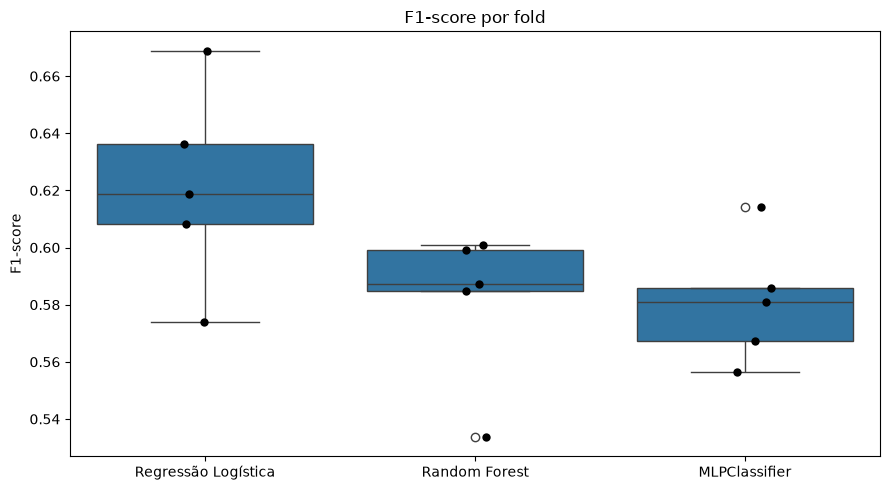

In [18]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=fold_results,
    x="Modelo",
    y="F1-score",
)

sns.stripplot(
    data=fold_results,
    x="Modelo",
    y="F1-score",
    color="black",
    size=6,
)

plt.title("F1-score por fold")
plt.xlabel("")
plt.ylabel("F1-score")
plt.tight_layout()
plt.show()

## Conclusão

A validação cruzada estratificada permitiu avaliar o desempenho e a
estabilidade da Regressão Logística, da Random Forest e do MLPClassifier em
cinco diferentes divisões dos dados de treino.

A Regressão Logística apresentou o melhor desempenho médio, alcançando
F1-score de **0,6212**, recall de **0,5819** e ROC-AUC de **0,8588**. Embora
tenha apresentado uma variação um pouco maior de F1-score entre os folds,
seu resultado médio permaneceu superior ao dos demais modelos.

O MLPClassifier obteve a maior precision, com **0,6708**, mas apresentou
recall de **0,5130** e F1-score de **0,5810**. Isso indica que o modelo foi
ligeiramente mais preciso ao classificar clientes como churn, mas deixou de
identificar uma parcela maior dos clientes que efetivamente cancelaram.

A Random Forest obteve F1-score médio de **0,5811**, praticamente igual ao
MLPClassifier. Entretanto, apresentou métricas perfeitas nos dados de treino
e uma queda relevante na validação, evidenciando forte sobreajuste na
configuração avaliada.

Considerando o F1-score como métrica técnica principal, a capacidade de
identificar clientes em risco, a proximidade entre os resultados de treino
e validação, a interpretabilidade e o menor custo computacional, a Regressão
Logística foi selecionada como o melhor modelo nesta comparação.

Os resultados não descartam definitivamente os demais algoritmos, pois seu
desempenho ainda pode ser alterado por ajustes de hiperparâmetros. Entretanto,
a Regressão Logística permanece como principal candidata para as próximas
etapas e como referência para avaliar se a complexidade adicional de outros
modelos produz ganhos relevantes.

# 12. Treinar o modelo final

In [22]:
final_model = models["Regressão Logística"]

final_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Gender','Senior Citizen','Partner',...,'Monthly Charges','Total Charges', 'CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

# 13. Avaliação final

In [23]:
y_test_pred = final_model.predict(X_test)
y_test_proba = final_model.predict_proba(X_test)[:, 1]

final_test_metrics = pd.Series({
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(
        y_test,
        y_test_pred,
        zero_division=0,
    ),
    "Recall": recall_score(
        y_test,
        y_test_pred,
        zero_division=0,
    ),
    "F1-score": f1_score(
        y_test,
        y_test_pred,
        zero_division=0,
    ),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba),
}, name="Regressão Logística — teste final")

display(final_test_metrics.to_frame().style.format("{:.4f}"))

,Regressão Logística — teste final
Accuracy,0.8034
Precision,0.6456
Recall,0.5749
F1-score,0.6082
ROC-AUC,0.8487


In [24]:
final_test_metrics.to_csv(
    RESULTS_DIR / "final_model_test_metrics.csv",
    header=True,
)

# 14. Salvar o modelo final

In [26]:
MODELS_DIR = Path("../models")
MODELS_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODELS_DIR / "logistic_regression_final.joblib"

joblib.dump(final_model, MODEL_PATH)

print(f"Modelo salvo em: {MODEL_PATH}")

Modelo salvo em: ../models/logistic_regression_final.joblib


# 15. Verificação do modelo salvo

In [27]:
loaded_model = joblib.load(MODEL_PATH)

loaded_predictions = loaded_model.predict(X_test)

assert (loaded_predictions == y_test_pred).all()

print("Modelo carregado e validado com sucesso.")

Modelo carregado e validado com sucesso.


# 16. Features esperadas

In [28]:
FEATURES_PATH = MODELS_DIR / "logistic_regression_features.txt"

FEATURES_PATH.write_text(
    "\n".join(X_train.columns),
    encoding="utf-8",
)

print(f"Features registradas em: {FEATURES_PATH}")

Features registradas em: ../models/logistic_regression_features.txt
